Парная линейная регрессия
Цель работы
    Познакомиться с моделью парной линейной регрессии регрессии и методом градиентного спуска.

Содержание работы
Найти оценки параметров модели парной линейной регрессии прямыми вычислениями и палучить с помощью модели прогнозы результативного прознака.
Найти оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска.
Оценить качество построенной модели, сравнив на графике обучающую выборку и прогнозы.
Построить кривые обучения.

In [ ]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = np.array([3, 5, 7, 6, 9])
Y = np.array([3, 7, 11, 14, 15])
display(x, Y)

array([3, 5, 7, 6, 9])

array([ 3,  7, 11, 14, 15])

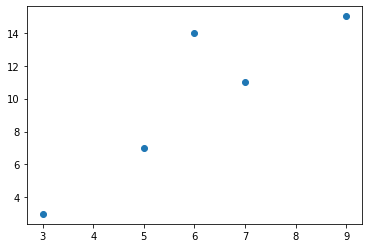

In [ ]:
#Изобразим их на графике
plt.figure()
plt.scatter(x, Y)
plt.show()

In [ ]:
#Вычислим оценки коэффициентов парной линейной регрессии по формулам
a1 = ((x - x.mean())*(Y - Y.mean())).mean()/((x - x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Модель линейной регрессии: Y^ = ", a0, " + ", a1, "* x")

Модель линейной регрессии: Y^ =  -2.0  +  2.0 * x


In [ ]:
#Дадим серию прогнозов Y^ для x от 3 до 9 с шагом 1
x_space = np.linspace(3, 9, 7)
print(x_space)
Y_pred = a0 + a1*x_space
print(Y_pred)

[3. 4. 5. 6. 7. 8. 9.]
[ 4.  6.  8. 10. 12. 14. 16.]


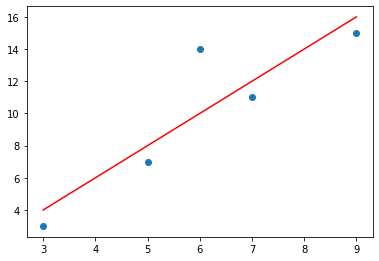

In [ ]:
#Изобразим на графике исходные данные и прогнозы 
fig  = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')
#ax.scatter(x_space, Y_pred)

In [ ]:
#Реализуем шаг градиентного спуска в модели парной лдинейной регрессии
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
    def predict(self, x):
        return self.a0 + self.a1*x
    def MSE(self, x, Y):
        return ((self.predict(x)-Y)**2).mean()
    def fit(self, x, Y):
        alpha = 0.1
        dT_a0 = -2*sum((Y -self.predict(x)))
        dT_a1 = -2*sum((Y -self.predict(x))*x)
        self.a0 -= alpha*dT_a0
        self.a1 -= alpha*dT_a1

In [ ]:
#Получим прогнозы до градиентного спуска с начальными значениями параметров
regr = SimpleRegression()
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print(regr.MSE(x, Y))

0
0
0
0
0
120.0


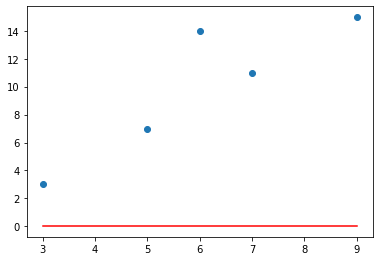

In [ ]:
#Выведем прогнозы до градиентного спуска на графике
x_space = np.linspace(3, 9, 7)
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

MSE после первого шага градиентного спуска:  183892.0


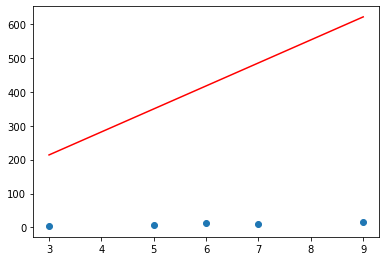

In [ ]:
#Реализуем шаг градиентного спуска
regr.fit(x, Y)
print("MSE после первого шага градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

In [ ]:
#Реализуем цикл градиентного спуска
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
    def predict(self, x):
        return self.a0 + self.a1*x
    def MSE(self, x, Y):
        return ((Y - self.predict(x))**2).mean()
    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()
    def MAPE(self, x, Y):
        return abs((Y - self.predict(x))/Y).mean()
    def fit(self, x, Y, alpha = 0.001, epsylon = 0.01, max_steps = 5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2*sum((Y -self.predict(x)))
            dT_a1 = -2*sum((Y -self.predict(x))*x)
            self.a0 -= alpha*dT_a0
            self.a1 -= alpha*dT_a1
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsylon:
                break
        return steps, errors

In [ ]:
#Запустим цикл градиентного спуска с заданной точностью 5
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.001, epsylon = 5)

5.004697916218
8.190462542210001
11.376227168202002
9.783344855206002
14.561991794194002
MSE после градиентного спуска:  4.709918696051655


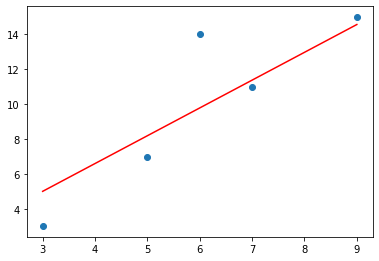

In [ ]:
#Выведем график  прогнозов и вычислим MSE
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

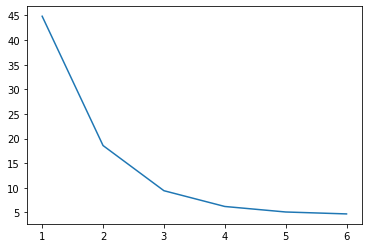

In [ ]:
#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

In [ ]:
#Запустим цикл градиентного спуска с заданной точностью 0.05
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.001, epsylon = 0.05)

MSE после градиентного спуска:  4.1903709155046345


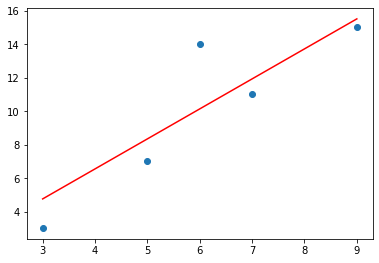

In [ ]:
#Выведем график прогнозов и вычислим MSE
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

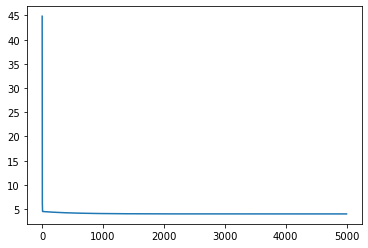

In [ ]:
#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

MSE после градиентного спуска:  4.1903709155046345


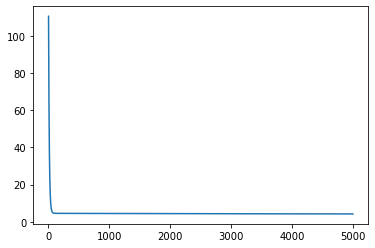

In [ ]:
#Запустим цикл градиентного спуска с разными значениями скорости обучения alpha=0.0001, 0.01, 0.1, 1, 10, ..., 
#с различной допукстимой точностью epsylon = 0.001, 0.5, 5, с различным максимальным количеством шагов max_steps
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.0001, epsylon = 0.01, max_steps = 5000)
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
plt.figure()
plt.plot(steps, errors)

Загрузите файл Гиперспектр кукурузы.csv (с помощью pd.read_csv).

1. Вычислите аналитическим путем оценки коэффициентов парной линейной регрессии и постройте ее график.
2. Найдите оценки параметров модели парной лиенйной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей сравнив на графике обучающую выборку и прогнозы.


Количество точек: 50
Диапазон x: 0.69036 - 0.79914


array([0.69036, 0.69258, 0.6948 , 0.69702, 0.69924])

array([0.17, 0.19, 0.19, 0.21, 0.22])

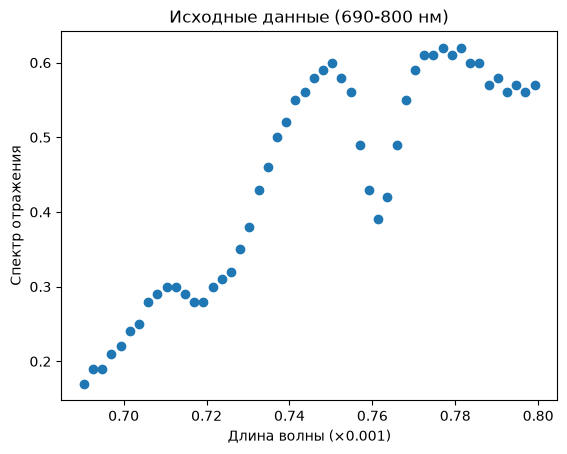

Модель регрессии (аналитически): Y^ =  -25.817963366736894  +  66.54874118053542 * x +  -41.93395061794052 * x^2


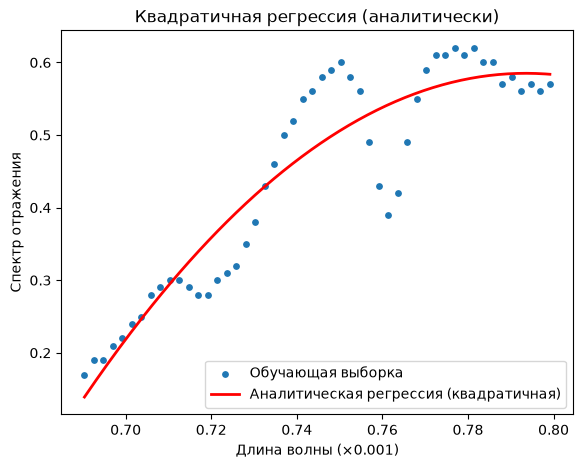

MSE после градиентного спуска:  0.004559361024011728
Количество шагов: 100000
Модель (градиентный спуск): Y^ =  -1.986529931237521  +  2.450741354774791 * x +  1.086501564399809 * x^2


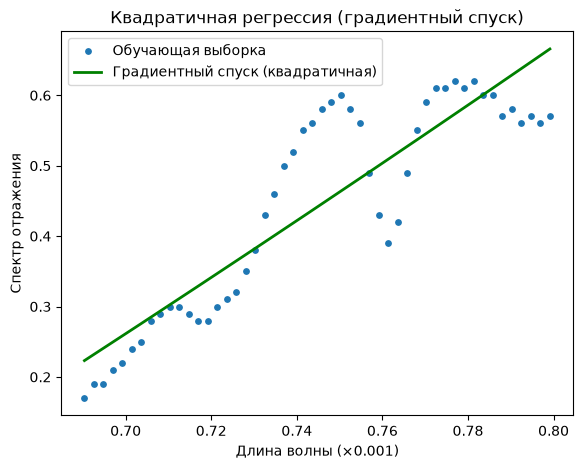

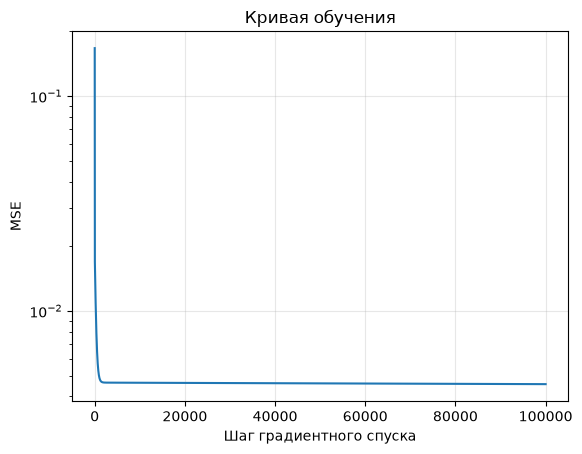

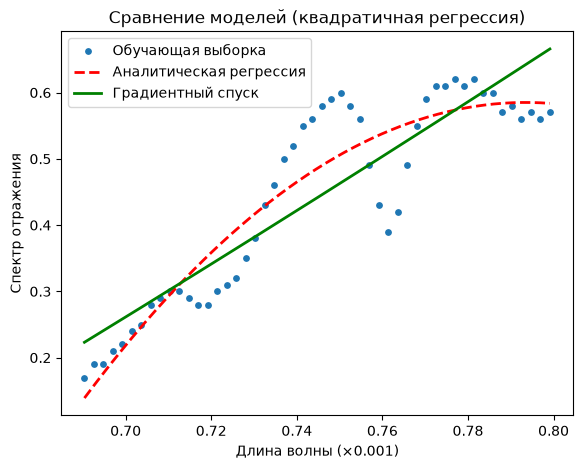

Метрика    Аналитически         Градиентный спуск   
MSE        0.003001             0.004559            
MAE        0.043038             0.055414            
MAPE       0.104500             0.130593            


In [3]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Загрузим данные
gipers = pd.read_csv(r"Гиперспектр кукурузы.csv", sep=';', decimal=',')
gipers.head()

#Переименуем столбцы
gipers.columns = ['wavelength', 'Spectr']

#Выберем участок 690-800 нм (red edge + начало NIR) - не менее 50 точек
mask = (gipers['wavelength'] >= 690) & (gipers['wavelength'] <= 800)
data = gipers[mask].copy()

#Исходные данные: x - длина волны, Y - спектр отражения
#Умножаем значения аргументов на 0.001 (по требованию задания)
x = data['wavelength'].values * 0.001
Y = data['Spectr'].values
print("Количество точек:", len(x))
print("Диапазон x:", x.min(), "-", x.max())
display(x[:5], Y[:5])

#Изобразим их на графике
plt.figure()
plt.scatter(x, Y)
plt.xlabel('Длина волны (×0.001)')
plt.ylabel('Спектр отражения')
plt.title('Исходные данные (690-800 нм)')
plt.show()

#Построим матрицу признаков X = [1, x, x^2]
X = np.column_stack([np.ones_like(x), x, x**2])

#Аналитическое решение МНК: a = (X^T X)^(-1) X^T Y
a = np.linalg.inv(X.T @ X) @ X.T @ Y
a0, a1, a2 = a
print("Модель регрессии (аналитически): Y^ = ", a0, " + ", a1, "* x + ", a2, "* x^2")

#Дадим серию прогнозов Y^ для x от минимального до максимального значения
x_space = np.linspace(x.min(), x.max(), 200)
Y_pred = a0 + a1*x_space + a2*x_space**2

#Изобразим на графике исходные данные и прогнозы
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y, s=15, label='Обучающая выборка')
ax.plot(x_space, Y_pred, 'r', linewidth=2, label='Аналитическая регрессия (квадратичная)')
ax.set_xlabel('Длина волны (×0.001)')
ax.set_ylabel('Спектр отражения')
ax.set_title('Квадратичная регрессия (аналитически)')
ax.legend()
plt.show()

#Реализуем цикл градиентного спуска для квадратичной модели
class QuadraticRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
        self.a2 = 0
    def predict(self, x):
        return self.a0 + self.a1*x + self.a2*x**2
    def MSE(self, x, Y):
        return ((Y - self.predict(x))**2).mean()
    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()
    def MAPE(self, x, Y):
        return abs((Y - self.predict(x))/Y).mean()
    def fit(self, x, Y, alpha = 0.001, epsylon = 0.01, max_steps = 5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2*np.mean(Y - self.predict(x))
            dT_a1 = -2*np.mean((Y - self.predict(x))*x)
            dT_a2 = -2*np.mean((Y - self.predict(x))*x**2)
            self.a0 -= alpha*dT_a0
            self.a1 -= alpha*dT_a1
            self.a2 -= alpha*dT_a2
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsylon:
                break
        return steps, errors

#Запустим цикл градиентного спуска
regr = QuadraticRegression()
steps, errors = regr.fit(x, Y, alpha = 0.5, epsylon = 1e-8, max_steps = 100000)
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
print("Количество шагов:", len(steps))
print("Модель (градиентный спуск): Y^ = ", regr.a0, " + ", regr.a1, "* x + ", regr.a2, "* x^2")

#Выведем график прогнозов
Y_pred_gd = regr.a0 + regr.a1*x_space + regr.a2*x_space**2
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y, s=15, label='Обучающая выборка')
ax.plot(x_space, Y_pred_gd, 'g', linewidth=2, label='Градиентный спуск (квадратичная)')
ax.set_xlabel('Длина волны (×0.001)')
ax.set_ylabel('Спектр отражения')
ax.set_title('Квадратичная регрессия (градиентный спуск)')
ax.legend()
plt.show()

#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)
plt.xlabel('Шаг градиентного спуска')
plt.ylabel('MSE')
plt.title('Кривая обучения')
plt.yscale('log')
plt.grid(True, alpha=0.3)
plt.show()

#Сравним аналитическую модель и градиентный спуск на одном графике
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y, s=15, label='Обучающая выборка')
ax.plot(x_space, Y_pred, 'r--', linewidth=2, label='Аналитическая регрессия')
ax.plot(x_space, Y_pred_gd, 'g', linewidth=2, label='Градиентный спуск')
ax.set_xlabel('Длина волны (×0.001)')
ax.set_ylabel('Спектр отражения')
ax.set_title('Сравнение моделей (квадратичная регрессия)')
ax.legend()
plt.show()

#Вычислим метрики качества для обеих моделей
regr_analytic = QuadraticRegression()
regr_analytic.a0 = a0
regr_analytic.a1 = a1
regr_analytic.a2 = a2

regr_gd = QuadraticRegression()
regr_gd.a0 = regr.a0
regr_gd.a1 = regr.a1
regr_gd.a2 = regr.a2

print("=" * 60)
print(f"{'Метрика':<10} {'Аналитически':<20} {'Градиентный спуск':<20}")
print("=" * 60)
print(f"{'MSE':<10} {regr_analytic.MSE(x, Y):<20.6f} {regr_gd.MSE(x, Y):<20.6f}")
print(f"{'MAE':<10} {regr_analytic.MAE(x, Y):<20.6f} {regr_gd.MAE(x, Y):<20.6f}")
print(f"{'MAPE':<10} {regr_analytic.MAPE(x, Y):<20.6f} {regr_gd.MAPE(x, Y):<20.6f}")
print("=" * 60)